# NBA Game Outcome Prediction — Demo

Predict the winner of NBA games from historical box-score data.

This notebook is a thin narrative over the `nba_predictor` package: it loads the
data, builds features, evaluates the models with season-based backtesting, and
predicts a few upcoming games. All the real logic lives in `src/nba_predictor/`.

**Pipeline:** `data` → `features` → `backtest` → `predict`.

In [1]:
import sys
from pathlib import Path

# Find the repo root whether this is run from the repo root or from notebooks/.
ROOT = Path.cwd()
if not (ROOT / "src" / "nba_predictor").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

from nba_predictor.data import load_games
from nba_predictor.features import build_features
from nba_predictor.models import build_models, select_features
from nba_predictor.backtest import ensemble_backtest, accuracy
from nba_predictor.predict import predict_games

## 1. Load the data

One row = one team's view of one game. `load_games` reads the CSV, drops
duplicate games and junk columns, parses dates, and sorts chronologically.

In [2]:
data_path = ROOT / "data" / "processed" / "games.csv"
if not data_path.exists():
    data_path = ROOT / "data" / "sample" / "games_sample.csv"  # committed fallback

games = load_games(data_path)
print(f"Loaded {len(games):,} rows from {data_path.relative_to(ROOT)}")
games[["date", "team", "team_opp", "home", "season", "won"]].head()

Loaded 25,348 rows from data/processed/games.csv


,date,team,team_opp,home,season,won
0,2016-10-25,GSW,SAS,1,2017,False
1,2016-10-25,POR,UTA,1,2017,True
2,2016-10-25,CLE,NYK,1,2017,True
3,2016-10-25,SAS,GSW,0,2017,True
4,2016-10-25,UTA,POR,0,2017,False


## 2. Build features

For each game we engineer: the next-game label (`target`), Elo rating, rolling
averages of the last 10 games, win/lose streaks, home/away win rate, and the
head-to-head record against the next opponent. Every feature uses past games
only — no leakage.

In [3]:
feat = build_features(games)
features = select_features(feat)
print(f"{feat.shape[0]:,} rows, {len(features)} predictor columns")
feat[["date", "team", "team_opp", "elo_pre", "elo_diff",
      "win_streak", "home_wr", "h2h_wr_next", "target"]].tail()

25,348 rows, 160 predictor columns


,date,team,team_opp,elo_pre,elo_diff,win_streak,home_wr,h2h_wr_next,target
25343,2026-06-08,NYK,SAS,1713.192490,3.957495,0,0.532864,0.545455,True
25344,2026-06-10,NYK,SAS,1703.078590,-16.270307,1,0.531616,0.521739,True
25345,2026-06-10,SAS,NYK,1719.348897,16.270307,0,0.561151,0.478261,False
25346,2026-06-13,NYK,SAS,1713.546545,4.665603,2,0.531616,0.500000,NaN
25347,2026-06-13,SAS,NYK,1708.880942,-4.665603,0,0.559809,0.500000,NaN


## 3. Backtest (season-by-season walk-forward)

Train on past seasons, test on the next one, step forward. This is the honest
way to validate a time-series model — a random split would train on the future.
We score Ridge, XGBoost, Logistic Regression, and their majority-vote ensemble.

In [4]:
ensemble, scores = ensemble_backtest(feat, build_models(), features, start_index=2)

for name, acc in scores.items():
    print(f"{name:9} {acc * 100:5.2f}%")

baseline = (feat["target"].dropna() == 1).mean()
print(f"\nbaseline  {baseline * 100:5.2f}%  (coin flip)")

ridge     60.31%
xgb       60.36%
logreg    60.38%
ensemble  60.50%

baseline  50.00%  (coin flip)


### Confusion matrix (ensemble)

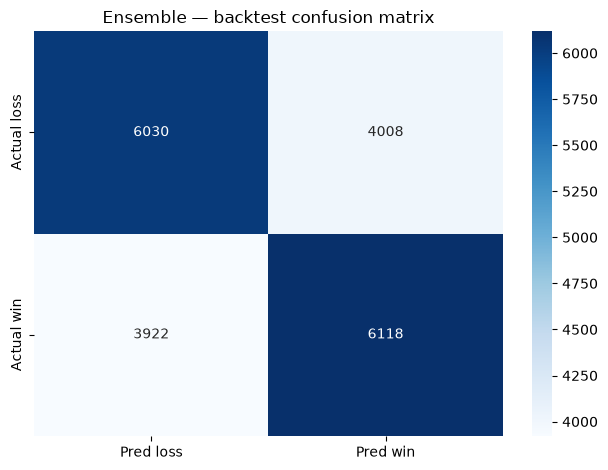

In [5]:
cm = confusion_matrix(ensemble["actual"], ensemble["prediction"])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred loss", "Pred win"],
            yticklabels=["Actual loss", "Actual win"])
plt.title("Ensemble — backtest confusion matrix")
plt.tight_layout()
plt.show()

## 4. Predict upcoming games

`predict_games` takes the current state of each team and predicts a winner for
any matchups you give it — no interactive prompts.

In [6]:
upcoming = [
    ("BOS", "LAL"),
    ("DEN", "GSW"),
    ("MIA", "NYK"),
]

model = build_models()["xgb"]
predict_games(feat, model, upcoming)

,date,home,away,p_home_win,predicted_winner
0,None,BOS,LAL,0.597,BOS
1,None,DEN,GSW,0.644,DEN
2,None,MIA,NYK,0.481,NYK


## 5. Conclusions & next steps

- The ensemble reaches roughly **60%** accuracy on honest, leak-free,
  season-based validation, well above the 50% baseline.
- This is lower than naive numbers you get from leaky setups (duplicate rows,
  scaling on the whole dataset) — and that honesty is the point.

**What could be added:** player-level stats and injuries, rest days / travel,
margin-of-victory in the Elo update, probability calibration, and a
high-confidence threshold for selective betting-style predictions.

*(To include the neural network, pass `build_models(include_nn=True)` — it loads
TensorFlow and takes longer to train.)*